<center><h1>Prado_Mario_HW5</h1></center>
<br>
<br>

Name: Mario Prado
<br>
Github Username: mrpradooo
<br>
USC ID: 4223775338

## 1. Decision Trees as Interpretable Models

Import packages

In [67]:
import os, warnings
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import (cross_val_score, KFold, RepeatedStratifiedKFold, GridSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
DATA = '../data'
SEED = 552


### (a) Obtain Data

Get the Accute Inamations Data Set

In [3]:
columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra',
        'd1_bladder_inflammation', 'd2_nephritis']
 
accute = pd.read_csv(os.path.join(DATA, 'diagnosis.data'), sep='\t', header=None, names=columns,
                    encoding='utf-16', decimal=',')

for col in columns[1:]:
    accute[col] = accute[col].str.strip().map({'yes':1, 'no':0})

SYMPTOMS = columns[:6]
RESULTS = columns[6:]
print(accute.shape, '|missing values:', accute.isna().sum().sum())
accute.head()

(120, 8) |missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,d1_bladder_inflammation,d2_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

label
bladder inflammation only             40
nephritis only                        31
no inflammation, no nephritis         30
bladder inflammation AND nephritis    19

Full tree: depth 4, 6 leaves, training accuracy 1.000


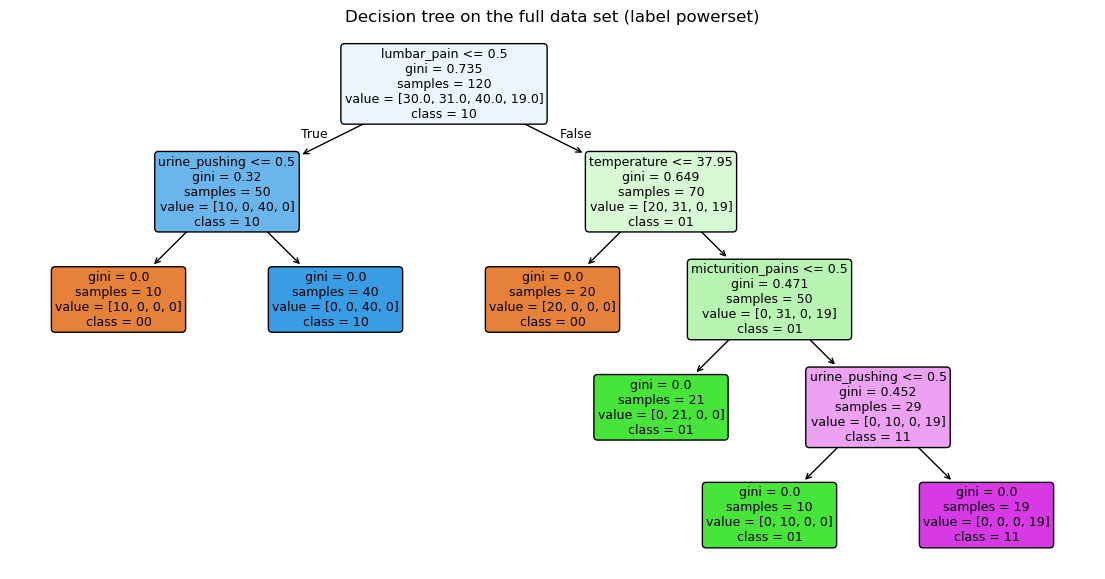

In [8]:
accute['label'] = accute['d1_bladder_inflammation'].astype(str) + accute['d2_nephritis'].astype(str)
CLASS_DESC = {'00': 'no inflammation, no nephritis',
                 '10': 'bladder inflammation only',
                 '01': 'nephritis only',
                 '11': 'bladder inflammation AND nephritis'}
print(accute['label'].value_counts().rename(index=CLASS_DESC).to_string())

X1, y1 = accute[SYMPTOMS], accute['label']
tree_full = DecisionTreeClassifier(random_state=SEED).fit(X1, y1)
print(f'\nFull tree: depth {tree_full.get_depth()}, {tree_full.get_n_leaves()} leaves, '
      f'training accuracy {tree_full.score(X1, y1):.3f}')

plt.figure(figsize=(14, 7))
plot_tree(tree_full, feature_names=SYMPTOMS, class_names=list(tree_full.classes_),
          filled=True, rounded=True, impurity=True, fontsize=9)
plt.title('Decision tree on the full data set (label powerset)')
plt.show()

### (c) Convert the decision rules

In [13]:
BIN = set(SYMPTOMS) - {'temperature'}

def status(name, threshold, left):
    # Rewrite split as readable text
    if name in BIN:
        return f'{name} = {"no" if left else "yes"}'
    return f'{name} <= {threshold:.2f}' if left else f'{name} > {threshold:.2f}'

def tree_to_rules(tree, feats_names):
    t = tree.tree_
    rules = []
    def tree_unfold(node, conds):
        if t.feature[node] == _tree.TREE_UNDEFINED:          
            counts = t.value[node][0]
            cls = tree.classes_[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            rules.append((conds, cls, n))
            return
        name, thr = feats_names[t.feature[node]], t.threshold[node]
        tree_unfold(t.children_left[node], conds + [status(name, thr, True)])
        tree_unfold(t.children_right[node], conds + [status(name, thr, False)])
    tree_unfold(0, [])
    return rules

def show_rules(tree):
    for i, (conds, cls, n) in enumerate(tree_to_rules(tree, SYMPTOMS), start=1):
        print(f'Rule {i}: IF ' + ' AND '.join(conds))
        print(f'         THEN class {cls} ({CLASS_DESC[cls]})   [{n} patients]')

show_rules(tree_full)

Rule 1: IF lumbar_pain = no AND urine_pushing = no
         THEN class 00 (no inflammation, no nephritis)   [10 patients]
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
         THEN class 10 (bladder inflammation only)   [40 patients]
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
         THEN class 00 (no inflammation, no nephritis)   [20 patients]
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
         THEN class 01 (nephritis only)   [21 patients]
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
         THEN class 01 (nephritis only)   [10 patients]
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
         THEN class 11 (bladder inflammation AND nephritis)   [19 patients]


(d)

 ccp_alpha  leaves  depth  train accuracy  CV accuracy  CV sd
    0.0000       6      4          1.0000       0.9892 0.0217
    0.0982       4      2          0.8417       0.8492 0.0606
    0.1333       3      2          0.7583       0.7583 0.0553
    0.1820       2      1          0.5917       0.6758 0.0652
    0.2229       1      0          0.3333       0.4900 0.1229


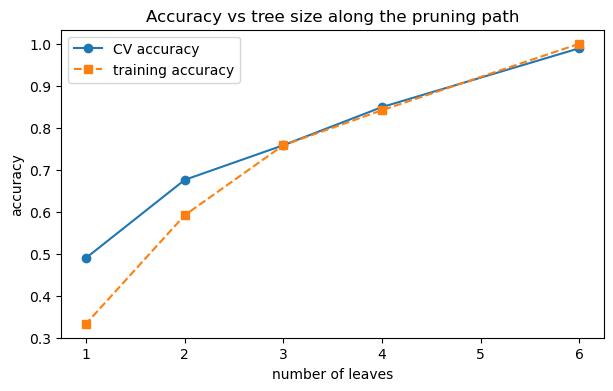

In [19]:
path = tree_full.cost_complexity_pruning_path(X1, y1)
fold_1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

rows = []
for alph in path.ccp_alphas:
    t = DecisionTreeClassifier(random_state=SEED, ccp_alpha=alph)
    scores = cross_val_score(t, X1, y1, cv=fold_1)
    t.fit(X1, y1)
    rows.append({'ccp_alpha': alph, 'leaves': t.get_n_leaves(), 'depth': t.get_depth(),
                 'train accuracy': t.score(X1, y1), 'CV accuracy': scores.mean(), 'CV sd': scores.std()})
prune = pd.DataFrame(rows)
print(prune.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prune['leaves'], prune['CV accuracy'], 'o-', label='CV accuracy')
ax.plot(prune['leaves'], prune['train accuracy'], 's--', label='training accuracy')
ax.set(xlabel='number of leaves', ylabel='accuracy', title='Accuracy vs tree size along the pruning path')
ax.legend(); plt.show()

In [23]:
best_tree = prune['CV accuracy'].max()
std_error = prune.loc[prune['CV accuracy'].idxmax(), 'CV sd'] / np.sqrt(fold_1.get_n_splits())
okay = prune[prune['CV accuracy'] >= best_tree - std_error]
chosen_alpha = okay['ccp_alpha'].max()
post_pruning_tree = DecisionTreeClassifier(random_state=SEED, ccp_alpha=chosen_alpha).fit(X1, y1)
print(f'best CV accuracy = {best_tree:.4f}, 1-SE cutoff = {best_tree - std_error:.4f}')
print(f'chosen ccp_alpha = {chosen_alpha:.4f} -> {post_pruning_tree.get_n_leaves()} leaves, '
      f'training accuracy {post_pruning_tree.score(X1, y1):.3f}\n')
print_rules(post_pruning_tree)

best CV accuracy = 0.9892, 1-SE cutoff = 0.9861
chosen ccp_alpha = 0.0000 -> 6 leaves, training accuracy 1.000

Rule 1: IF lumbar_pain = no AND urine_pushing = no
         THEN class 00 (no inflammation, no nephritis)   [10 patients]
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
         THEN class 10 (bladder inflammation only)   [40 patients]
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
         THEN class 00 (no inflammation, no nephritis)   [20 patients]
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
         THEN class 01 (nephritis only)   [21 patients]
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
         THEN class 01 (nephritis only)   [10 patients]
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
         THEN class 11 (bladder inflammation AND nephritis)   [19 patients]


We can actually see from our data that there are five possible subtrees those with 6, 4,3,2, and 1 leaves. The one with 6 leaves has the highest accuracy at 98% and after one round of pruning to 84.9%. So if we're following the 1 - SE rule then alpha remains 0 and we pick the 6-leaf tree as our minimal decision tree.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [ ]:
names = [line.split()[1] for line in open(os.path.join(DATA, 'communities.names')) if line.startswith('@attribute')]
crime = pd.read_csv(os.path.join(DATA, 'communities.data'), header=None, names=names, na_values='?')
print('shape:', crime.shape)

TARGET = 'ViolentCrimesPerPop'
train_raw = crime.iloc[:1495]
test_raw = crime.iloc[1495:]      
print('train:', train_raw.shape, ' test:', test_raw.shape)

shape: (1994, 128)
train: (1495, 128)  test: (499, 128)


### (b) Missing values

In [27]:
NON_PREDICTS = ['state', 'county', 'community', 'communityname', 'fold']
FEATURES = [c for c in crime.columns if c not in NON_PREDICTS + [TARGET]]
print(len(FEATURES), 'predictive features')

missing_vals = crime[FEATURES].isna().sum()
missing_vals = missing_vals[missing_vals > 0].sort_values(ascending=False)
print(f'\n{len(missing_vals)} features have missing values:')
print(missing_vals.to_string())

122 predictive features

23 features have missing values:
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasTotalReq           1675
LemasSwFTFieldPerPop    1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
OfficAssgnDrugUnits     1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
PolicOperBudg           1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
LemasGangUnitDeploy     1675
LemasPctPolicOnPatr     1675
PolicBudgPerPop         1675
OtherPerCap                1


In [31]:
imputer = SimpleImputer(strategy='median').fit(train_raw[FEATURES])
X_train = pd.DataFrame(imputer.transform(train_raw[FEATURES]), columns=FEATURES)
X_test = pd.DataFrame(imputer.transform(test_raw[FEATURES]), columns=FEATURES)
y_train = train_raw[TARGET].to_numpy()
y_test = test_raw[TARGET].to_numpy()
print('missing after imputation:', int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
X_all = pd.concat([X_train, X_test], ignore_index=True)

missing after imputation: 0


We see saw that in total 23 features have missing values.

### (c) Plot a correlation matrix

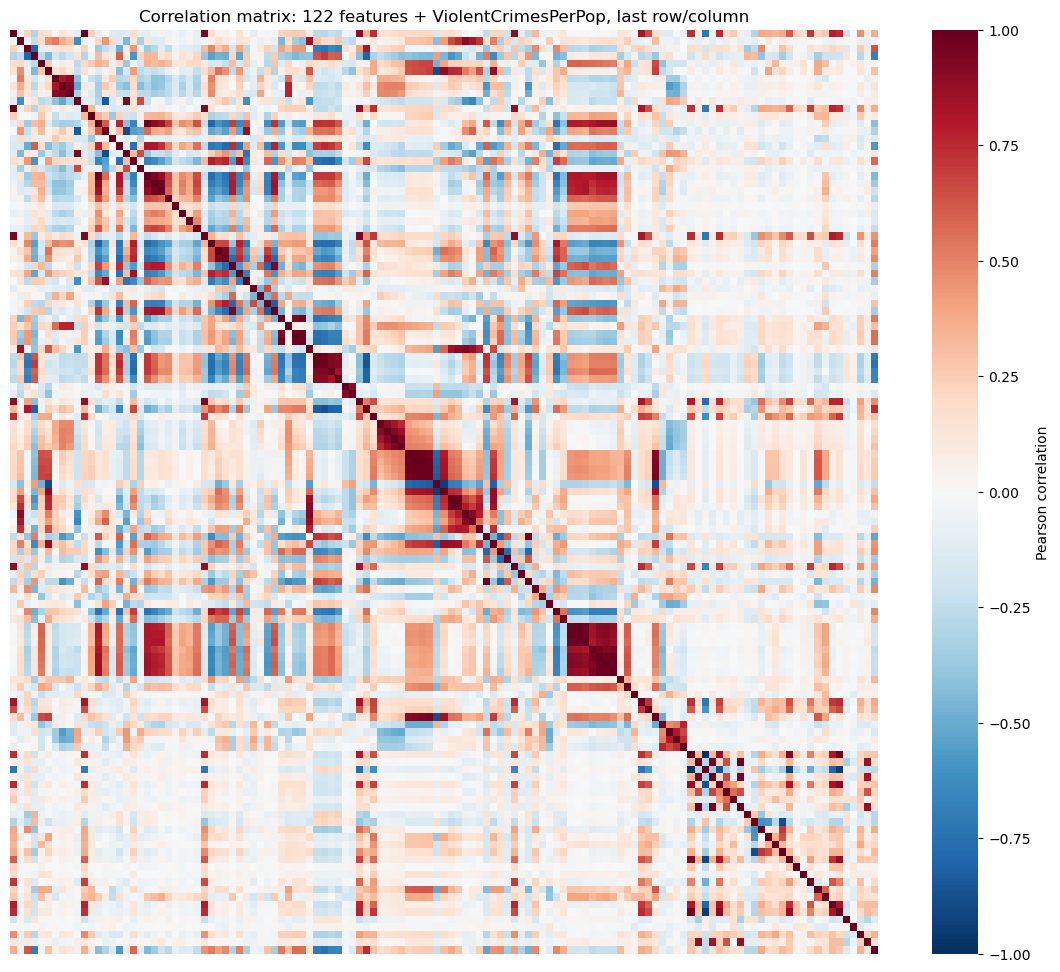

Features most correlated with the target:
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556

Feature pairs with r > 0.9: 58


In [32]:
correlation_matrix = pd.concat([X_all, pd.Series(np.r_[y_train, y_test], name=TARGET)], axis=1).corr()
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, cmap='RdBu_r', vmin=-1, vmax=1, xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation matrix: 122 features + ViolentCrimesPerPop, last row/column')
plt.show()

print('Features most correlated with the target:')
print(correlation_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(10).round(3).to_string())

upper = correlation_matrix.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(FEATURES),) * 2, dtype=bool), k=1))
print(f'\nFeature pairs with r > 0.9: {(upper.abs() > 0.9).sum().sum()}')

Based off our correlation matrix results we can see that the features most correlated with violent crime are Pctkids2Par at -0.74 and PctIlleg at 0.74. 

### (d) Calculate the Coefficient of Variation CV

In [33]:
coef_var_feat = (X_all.std(ddof=1) / X_all.mean()).sort_values(ascending=False)
print(coef_var_feat.round(4).to_string())

PctPolicAsian            5.4478
NumStreet                4.4077
NumInShelters            3.4855
NumIlleg                 2.9942
NumImmig                 2.9005
LemasPctOfficDrugUn      2.5553
NumUnderPov              2.3050
population               2.2035
LemasSwornFT             2.0807
numbUrban                2.0017
HousVacant               1.9588
LandArea                 1.6780
racePctHisp              1.6143
PolicOperBudg            1.5629
PctNotSpeakEnglWell      1.4591
PctUsePubTrans           1.4167
racepctblack             1.4109
LemasTotalReq            1.3817
racePctAsian             1.3592
PctPolicHisp             1.3263
PctRecentImmig           1.3001
PctRecImmig5             1.2976
PctRecImmig10            1.2840
PctRecImmig8             1.2812
PctPersDenseHous         1.1272
OfficAssgnDrugUnits      1.0886
PolicCars                1.0876
PctForeignBorn           1.0723
PctVacantBoarded         1.0647
PctIlleg                 0.9198
PctHousNoPhone           0.9182
OwnOccMe

### (e) Scatter plots and box plots for highest CV features

11 features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


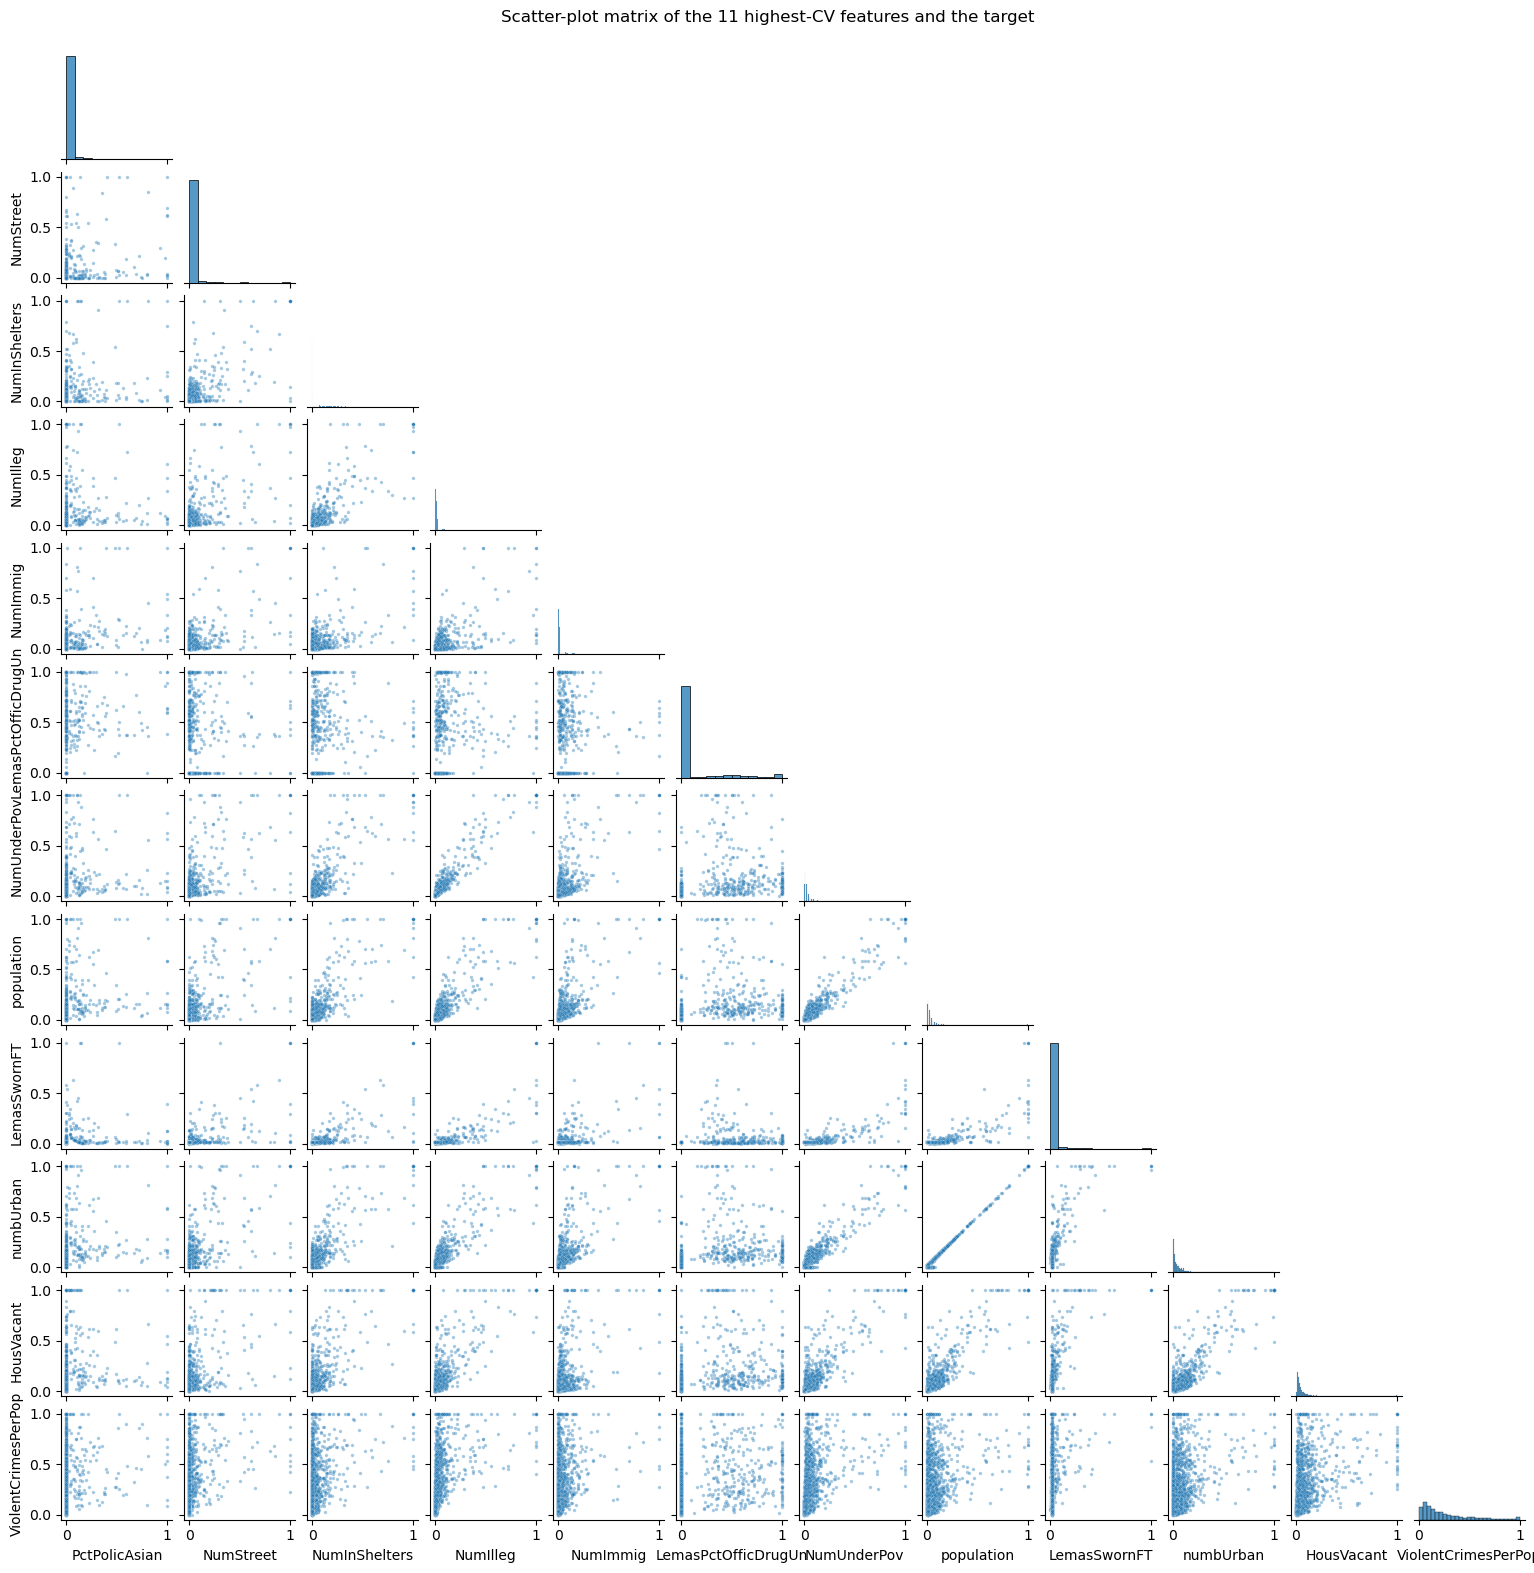

In [37]:
m = int(np.floor(np.sqrt(128)))
top = coef_var_feat.head(m).index.tolist()
print(m, 'features:', top)

plot_dataf = X_all[top].copy()
plot_dataf[TARGET] = np.r_[y_train, y_test]
n = sns.pairplot(plot_dataf, corner=True, plot_kws={'s': 6, 'alpha': .4}, height=1.3)
n.fig.suptitle('Scatter-plot matrix of the 11 highest-CV features and the target', y=1.01)
plt.show()

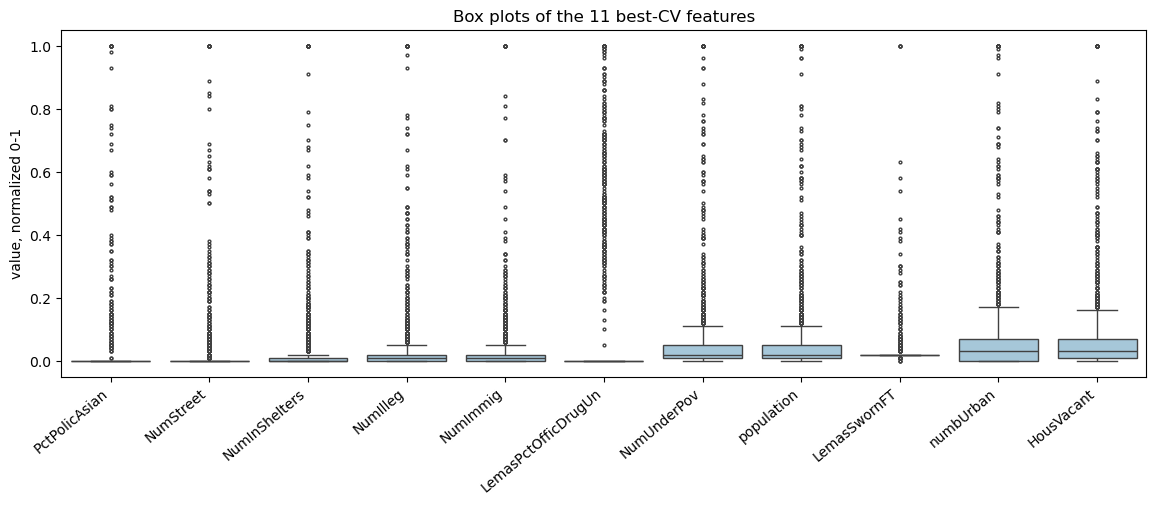

In [38]:
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=X_all[top], ax=ax, color='#9ecae1', fliersize=2)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
ax.set(ylabel='value, normalized 0-1', title='Box plots of the 11 best-CV features')
plt.show()

So the 11 features I ended up picking were PCtPolicAsian, NumStreet, NumInShelters, NumIlleg, NumImmig, LemasPctOfficDrugUn, NumUnderPov, population, LemasSwornFt, numbUrban, and HousVacant. No scatterplots are not enough for a couple of reasons firstly, scatter pltos only show the relationship between one feature and the target. The real world is much different as many variabel ahv eot be taken into account to get accurate readings. We also see that are data seems to be a quite skewed to the right the box plots clearly prove this as most medians are around 0 so having small means will jsut inflate our CV.  

### (f) Fit a linear model

In [44]:
answers = {}       

def report(name, model, Xte=X_test):
    prediction = model.predict(Xte)
    answers[name] = mean_squared_error(y_test, prediction)
    print(f'{name}: test MSE = {answers[name]:.5f}, test R2 = {r2_score(y_test, prediction):.4f}')

ols = LinearRegression().fit(X_train, y_train)
report('OLS', ols)
baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f'(baseline  = {baseline:.5f})')

OLS: test MSE = 0.01797, test R2 = 0.6222
(baseline  = 0.04767)


### (g) Fit a ridge regression model

In [46]:
k_fold = KFold(n_splits=10, shuffle=True, random_state=SEED)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 61), cv=k_fold).fit(X_train, y_train)
print(f'lambda: {ridge.alpha_:.4f}')
report('Ridge', ridge)

lambda: 2.5119
Ridge: test MSE = 0.01751, test R2 = 0.6319


### (h) Fit a LASSO model

In [50]:
lasso = LassoCV(cv=k_fold, random_state=SEED, max_iter=100000).fit(X_train, y_train)
selected_vars = [f for f, c in zip(FEATURES, lasso.coef_) if c != 0]
print(f'lambda: {lasso.alpha_:.6f}')
report('LASSO, raw features', lasso)
print(f'\n{len(selected_vars)} of {len(FEATURES)} selected variables:')
print(', '.join(selected_vars))

lambda: 0.000082
LASSO, raw features: test MSE = 0.01769, test R2 = 0.6281

79 of 122 selected variables:
racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSam

In [57]:
lasso_standard = make_pipeline(StandardScaler(), LassoCV(cv=k_fold, random_state=SEED, max_iter=100000)).fit(X_train, y_train)
selected_standard = [f for f, c in zip(FEATURES, lasso_standard[-1].coef_) if c != 0]
print(f'lambda chosen by 10-fold CV: {lasso_standard[-1].alpha_:.6f}')
report('LASSO, stndrd)', lasso_standard)
print(f'\n{len(selected_standard)} of {len(FEATURES)} variables selected:')
print(', '.join(selected_standard))

both = set(selected_vars) & set(selected_standard)
print(f'\nselected by both: {len(both)}; only raw: {sorted(set(selected_vars) - set(selected_standard))}; '
      f'only stndrd: {sorted(set(selected_standard) - set(selected_vars))}')

lambda chosen by 10-fold CV: 0.000619
LASSO, stndrd): test MSE = 0.01773, test R2 = 0.6272

76 of 122 variables selected:
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPe

We actually see that the two test errors are really really similar almsot identical. For regular lasso we get 0.0169 while for standardized lasso we get 0.01773. Although, this is kind of expected as our features were normalized before we did this.

### (i) Fit a PCR model

M: 96
PCR: test MSE = 0.01834, test R2 = 0.6143


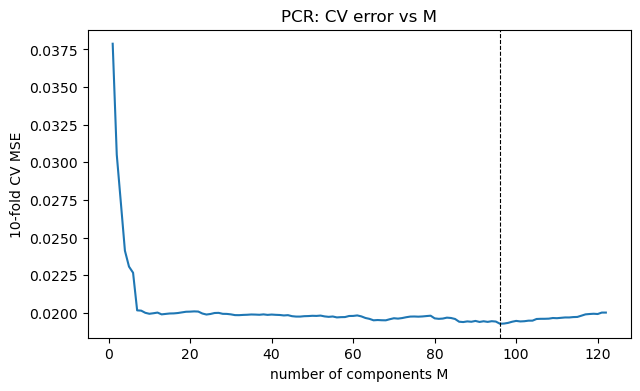

In [62]:
pcr_model = GridSearchCV(make_pipeline(PCA(), LinearRegression()),
                   {'pca__n_components': range(1, len(FEATURES) + 1)},
                   cv=k_fold, scoring='neg_mean_squared_error').fit(X_train, y_train)
M = pcr_model.best_params_['pca__n_components']
print(f'M: {M}')
report('PCR', pcr_model)

coefv_curve = -pcr_model.cv_results_['mean_test_score']
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(FEATURES) + 1), coefv_curve)
plt.axvline(M, color='k', ls='--', lw=.8)
plt.xlabel('number of components M'); plt.ylabel('10-fold CV MSE'); plt.title('PCR: CV error vs M')
plt.show()

We see that cross-validation picks an M value of 96 and our best test error is 0.01834. So out of the linear models this is actually the worst performer so far and that's because PCR doesn't gain anything from reducing our dimension count which is why it doesn't start doing good again until 96 components are reintroduced.

### (j) Fit a boosting tree

In [71]:
foundation = dict(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
            random_state=SEED, n_jobs=4)
alpha_grid = [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]
xgb_coeff_v = GridSearchCV(xgb.XGBRegressor(**foundation), {'reg_alpha': alpha_grid}, cv=k_fold,
                      scoring='neg_mean_squared_error').fit(X_train, y_train)
alpha_tab = pd.DataFrame({'reg_alpha': alpha_grid, 'CV MSE': -xgb_coeff_v.cv_results_['mean_test_score']})
print(alpha_tab.round(5).to_string(index=False))
print(f"\nalpha chosen: {xgb_coeff_v.best_params_['reg_alpha']}")
report('XGBoost', xgb_coeff_v)

 reg_alpha  CV MSE
     0.000 0.01907
     0.001 0.01915
     0.010 0.01912
     0.050 0.01921
     0.100 0.01906
     0.500 0.01897
     1.000 0.01896
     2.000 0.01898
     5.000 0.01943
    10.000 0.02063

alpha chosen: 1
XGBoost: test MSE = 0.01628, test R2 = 0.6578
